# 07-3. 단기 + 장기 메모리 결합: Checkpoint와 Store 함께 쓰기
## 학습 목표
- 07-1의 `ChatState` 대화 그래프에 07-2의 `InMemoryStore`를 결합한다.
- 같은 사용자(`user_id`)가 `thread_id`를 바꿔도 이름을 기억하는 과정을 관찰한다.
- 단기 메모리(Checkpoint)와 장기 메모리(Store)가 함께 쓰일 때 각각의 역할을 구분한다.

**준비:** OpenAI API 키가 필요하다. 07-1과 마찬가지로 `gpt-4o-mini`를 호출한다.

## 핵심 개념과 실행 전 예측
07-1에서는 같은 `thread_id`일 때만 대화가 이어졌고, `thread_id`가 바뀌면(Bob) 이전 대화를 전혀 몰랐다.

이번에는 Checkpoint(단기, `thread_id` 단위) 위에 Store(장기, `user_id` 단위)를 얹는다. 민지가 **스레드 1**에서 이름을 알려주고, **스레드 2**(새 `thread_id`, 같은 `user_id`)에서 "이름이 뭐였지?"라고 물으면 어떻게 될까?

Checkpoint만 보면 스레드 2는 빈 대화이므로 알 수 없어야 한다. 하지만 `chat_node`가 호출 전에 Store에서 사용자 이름을 조회해 System Message로 주입하면, 스레드가 달라져도 이름을 답할 수 있다. `user_id`가 다른 Bob은 여전히 모른다.

## 기본 설정

In [12]:
from langchain_core.globals import set_llm_cache, get_llm_cache
from langchain_core.caches import InMemoryCache
from common.ai_model import get_llm_model

# 동일한 프롬프트+모델 파라미터로 호출하면 API를 다시 부르지 않고
# 캐시된 응답을 즉시 반환한다. 커널을 재시작하면 캐시는 사라진다.
set_llm_cache(InMemoryCache())

llm_options = {"model": "gpt-4o-mini", "temperature": 0}

llm = get_llm_model(**llm_options)
print("사용 모델:", llm_options["model"])
print("캐시 종류:", type(get_llm_cache()).__name__)

사용 모델: gpt-4o-mini
캐시 종류: InMemoryCache


## 그래프 설계
State(`ChatState.messages`)는 07-1과 동일하게 단기 메모리를 담당한다.   
여기에 `context_schema=UserContext`를 추가해 Node 안에서 `runtime.store`로 장기 메모리(Store)에 접근한다.

`chat_node`는 두 가지 일을 한다.
1. LLM을 부르기 **전에** Store에서 저장된 이름을 조회해 System Message로 주입한다.
2. 이번 메시지에 이름이 새로 나오면 Store에 저장(갱신)한다.

In [13]:
import re
from dataclasses import dataclass
from typing import Annotated
from pydantic import BaseModel
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore
from langgraph.graph import START, END, StateGraph
from langgraph.graph.message import add_messages
from langgraph.runtime import Runtime

# MessagesState 대신 Pydantic으로 정의한 단기 메모리용 State. (07-1과 동일)
class ChatState(BaseModel):
    messages: Annotated[list, add_messages]

# 장기 메모리를 "누구의 것"으로 저장할지 지정하는 사용자 식별자. (07-2와 동일한 역할)
@dataclass
class UserContext:
    user_id: str

# "내 이름은 OO야/이야/입니다" 같은 문장에서 이름만 뽑아내는 간단한 패턴.
NAME_PATTERN = re.compile(r"내\s*이름은\s*(\S+?)(?:이야|야|입니다|이에요|예요)")

def chat_node(state: ChatState, runtime: Runtime[UserContext]) -> dict:
    namespace = ("profile", runtime.context.user_id)
    key = "name"

    # 1) Store(장기 메모리)에 저장된 이름이 있으면 System Message로 알려준다.
    extra_messages = []
    saved = runtime.store.get(namespace, key)
    if saved:
        extra_messages.append(
            SystemMessage(
                content=f"사용자의 이름은 '{saved.value['name']}'이다. 이미 알고 있으니 다시 묻지 말고 바로 답하라."
            )
        )

    # 2) 이번 메시지에 이름이 새로 나오면 Store에 저장(갱신)한다.
    last_text = state.messages[-1].content
    match = NAME_PATTERN.search(last_text)
    if match:
        runtime.store.put(namespace, key, {"name": match.group(1)})

    # 3) Checkpoint(단기 메모리)가 쌓아 둔 이번 스레드의 messages로 호출한다.
    response = llm.invoke(extra_messages + state.messages)
    return {"messages": [response]}

builder = StateGraph(ChatState, context_schema=UserContext)
builder.add_node("chat", chat_node)
builder.add_edge(START, "chat")
builder.add_edge("chat", END)

# Checkpointer(단기, thread_id)와 Store(장기, user_id)를 함께 등록한다.
checkpointer = InMemorySaver()
store = InMemoryStore()
graph = builder.compile(checkpointer=checkpointer, store=store)

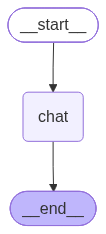

In [14]:
from common.utils import visualize_graph
visualize_graph(graph)

### 대화 스레드와 사용자 정의
민지는 두 개의 스레드(`thread_id`)를 쓰지만 `user_id`는 동일하다. Bob은 `thread_id`와 `user_id`가 모두 다르다.

In [15]:
minji = UserContext(user_id="learner-minji")
minji_thread1 = {"configurable": {"thread_id": "minji-thread-1"}}
minji_thread2 = {"configurable": {"thread_id": "minji-thread-2"}}

bob = UserContext(user_id="learner-bob")
bob_thread1 = {"configurable": {"thread_id": "bob-thread-1"}}

## 실습 A. 스레드 1에서 이름을 알려준다
07-1의 Alice 첫 대화와 같은 질문이다. 이번에는 `chat_node`가 답하는 동시에 Store에도 이름을 저장한다.

In [16]:
first = graph.invoke(
    {"messages": [HumanMessage(content="내 이름은 민지야. 이름만 기억해줘.")]},
    config=minji_thread1,
    context=minji,
)

In [17]:

print("스레드 1의 마지막 답:", first["messages"][-1].content)
print("스레드 1 메시지 수:", len(first["messages"]))
print("Store에 저장된 이름:", store.get(("profile", "learner-minji"), "name").value)

스레드 1의 마지막 답: 안녕하세요, 민지님! 이름을 기억할게요. 어떻게 도와드릴까요?
스레드 1 메시지 수: 2
Store에 저장된 이름: {'name': '민지'}


In [18]:
assert len(first["messages"]) == 2
assert store.get(("profile", "learner-minji"), "name").value["name"] == "민지"

## 실습 B. 새 스레드(같은 사용자)에서 이름을 묻는다
07-1이었다면 새 `thread_id`의 Checkpoint는 비어 있으므로 이름을 몰라야 한다. 이번에는 Store 덕분에 답할 수 있는지 실행 전에 예상한 뒤 확인한다.

In [19]:
second = graph.invoke(
    {"messages": [HumanMessage(content="내 이름이 뭐였지? 한 단어로 답해줘.")]},
    config=minji_thread2,
    context=minji,
)
print("스레드 2의 답:", second["messages"][-1].content)
print("스레드 2 메시지 수(Checkpoint 기준):", len(second["messages"]))
assert len(second["messages"]) == 2  # 이번 스레드의 Checkpoint에는 질문-답변 2개뿐이다.
assert "민지" in second["messages"][-1].content

스레드 2의 답: 민지.
스레드 2 메시지 수(Checkpoint 기준): 2


## 실습 C. 다른 사용자(Bob)는 여전히 모른다
`user_id`가 다르면 Store의 namespace도 달라서 민지의 정보에 접근할 수 없다.

In [20]:
other = graph.invoke(
    {"messages": [HumanMessage(content="내 이름이 뭐였지? 모르면 모른다고 답해줘.")]},
    config=bob_thread1,
    context=bob,
)

In [21]:

print("Bob의 답:", other["messages"][-1].content)
print("Bob Store 조회 결과:", store.get(("profile", "learner-bob"), "name"))
assert store.get(("profile", "learner-bob"), "name") is None

Bob의 답: 죄송하지만, 당신의 이름을 알 수 없습니다. 제가 개인 정보를 기억하거나 저장할 수 없기 때문입니다. 다른 질문이 있으면 도와드릴 수 있습니다!
Bob Store 조회 결과: None


## State(Checkpoint)와 Store 비교
스레드 2의 Checkpoint 메시지 수는 2개뿐이지만(`get_state`로 확인), 답은 스레드 1에서 저장한 이름을 알고 있다. 이것이 07-1과의 차이다: **단기 메모리만으로는 설명되지 않는 정보가 장기 메모리에서 채워진다.**

In [22]:
print("스레드 2 Checkpoint 메시지 수:", len(graph.get_state(minji_thread2).values["messages"]))
print("민지 Store 항목:", [item.value for item in store.search(("profile", "learner-minji"))])
print("Bob Store 항목:", [item.value for item in store.search(("profile", "learner-bob"))])

스레드 2 Checkpoint 메시지 수: 2
민지 Store 항목: [{'name': '민지'}]
Bob Store 항목: []


## 작은 수정 실습
민지가 세 번째 스레드에서 "이제부터 내 이름은 서연이야"라고 말하면 `NAME_PATTERN`이 다시 매칭되어 Store 값이 갱신되는지 확인한다. 이후 또 다른 새 스레드에서 다시 물어, 갱신된 이름이 나오는지 실행 전에 예측하고 확인한다. (힌트: `NAME_PATTERN`은 "내 이름은 OO야/이야/..." 형태만 인식한다. "민지 말고 서연이야"처럼 다른 어순은 인식하지 못하므로, 패턴을 직접 넓혀보는 것도 좋은 연습이다.)

## 이해 확인
1. 같은 `user_id`인데 `thread_id`가 바뀌어도 이름을 기억하는 이유는 무엇인가?
   **해설:** `chat_node`가 응답 전에 Store(namespace: `("profile", user_id)`)를 조회해 System Message로 주입하기 때문이다. 이 조회는 Checkpoint(스레드별 대화 State)와 무관하게 동작한다.
2. Bob이 같은 질문을 해도 모르는 이유는?
   **해설:** Store의 namespace가 `user_id`로 구분되어 있어 Bob의 namespace에는 아무 값도 없기 때문이다.
3. 07-1의 Checkpoint 역할과 이번 실습의 Store 역할을 한 문장씩 구분해서 설명해보라.
   **해설:** Checkpoint는 한 `thread_id`의 실행 State(`messages`)를 이어주고, Store는 `user_id` 같은 namespace 아래 정보를 스레드와 무관하게 저장·조회한다.

**핵심 정리:** 단기 메모리(Checkpoint)와 장기 메모리(Store)는 한 그래프 안에서 함께 쓸 수 있다. Node 안에서 Store를 먼저 조회해 프롬프트에 주입하고, 새 정보가 들어오면 Store에 다시 저장하는 패턴이 가장 기본적인 결합 방식이다.